This notebook accompanies [04-neural-networks](https://xing-phys.github.io/ai-for-physics/04-neural-networks.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Neural networks as adaptable physical representations 

## From fixed features to learned features

A polynomial force model succeeds when its features match the physics. In a many-body system, designing a manageable complete set of useful features becomes difficult. A neural network composes simple adjustable transformations so that its intermediate features adapt along with the final prediction. The basic idea is mathematical composition, not an assumption that a computer models a biological brain.

The prerequisites are regression and classification from Chapter 3. This chapter introduces layers, nonlinear activation, convolution, attention, and representation learning. Chapter 5 derives how their parameters are trained. Later chapters impose quantum, geometric, and dynamical structure on these building blocks.

## A network in equations

For an input $h^{(0)}=x\in\mathbb R^{d_0}$, a fully connected layer is

$$
z^{(\ell)}=W^{(\ell)}h^{(\ell-1)}+b^{(\ell)},\qquad
h^{(\ell)}=\varphi_\ell(z^{(\ell)}),
$$ 

where $W^{(\ell)}$ has shape $d_\ell\times d_{\ell-1}$ and the activation acts component by component unless specified otherwise. Weights and biases form the trainable parameter vector $\theta$. The output layer is chosen for the task: an unrestricted scalar for energy, softmax probabilities for classes, or a vector field with specified transformations.

If every activation is the identity, composition collapses to one affine map: $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$. Depth alone does not create nonlinear expressivity. Common nonlinearities include $\tanh z$, the rectified linear unit $\max(0,z)$ or ReLU, and smooth softplus $\log(1+e^z)$. Use a stable form of softplus to avoid exponent overflow.

ReLU is piecewise linear and has an undefined derivative at zero; implementations choose a convention there. A network built entirely from affine maps and ReLU has zero second derivatives within each linear region. It can fit function values well yet be poorly suited to a calculation requiring smooth second spatial derivatives, such as a kinetic-energy operator. A smooth activation may then be physically important.

For one hidden layer of width $m$ with scalar output,

$$
f_\theta(x)=c+\sum_{a=1}^m v_a\varphi(w_a^Tx+b_a).
$$

Each unit responds to a learned projection of the input; the output combines those responses. The parameter count is $m(d+2)+1$. A dense network taking every coordinate of a large system therefore spends parameters even on interactions known to be absent or equivalent. Locality and symmetry can reduce that waste.

## Worked construction: nonlinear features from hinges

Consider a continuous piecewise-linear function on the real line whose slope changes by $\Delta s_j$ at positions $t_j$. It can be written exactly as

$$
f(x)=a+s_0x+\sum_j\Delta s_j\max(0,x-t_j).
$$ 

To verify this, differentiate away from the breakpoints. Each hinge contributes zero for $x<t_j$ and $\Delta s_j$ for $x>t_j$. The total slope changes by exactly the prescribed amount. Choose $a$ to match one value; continuity then fixes the full function. The linear term itself can be represented by $x=\operatorname{ReLU}(x)-\operatorname{ReLU}(-x)$.

On a finite interval, interpolate a twice-differentiable $g$ at a grid of spacing $h$. The error on one interval is $g''(\xi)(x-t_j)(x-t_{j+1})/2$ for some interior $\xi$, so the maximum absolute error is at most $h^2\max|g''|/8$. This constructs a network approximation and makes its accuracy dependence explicit. It is an existence argument in one dimension, not a guarantee of efficient learning for arbitrary high-dimensional functions.

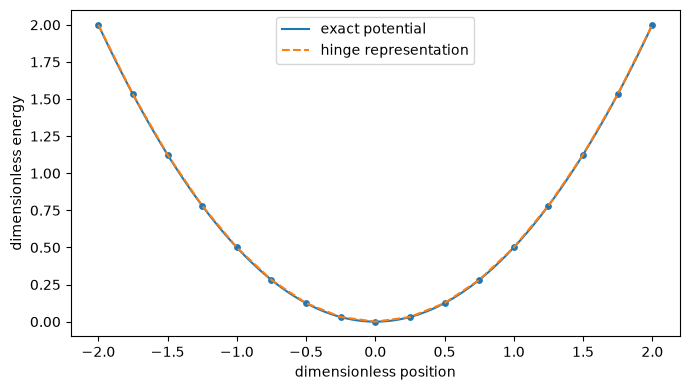

Maximum interpolation error: 0.007800


In [1]:
import numpy as np
import matplotlib.pyplot as plt
knots = np.linspace(-2, 2, 17)
values = 0.5*knots**2
slopes = np.diff(values)/np.diff(knots)
x = np.linspace(-2, 2, 401)
prediction = values[0] + slopes[0]*(x-knots[0])
for j in range(1, len(knots)-1):
    prediction += (slopes[j]-slopes[j-1])*np.maximum(0, x-knots[j])
bound = (knots[1]-knots[0])**2 / 8
assert np.max(np.abs(prediction-0.5*x*x)) <= bound + 1e-12
plt.figure(figsize=(7, 4))
plt.plot(x, .5*x*x, label='exact potential')
plt.plot(x, prediction, '--', label='hinge representation')
plt.scatter(knots, values, s=15)
plt.xlabel('dimensionless position'); plt.ylabel('dimensionless energy')
plt.legend(); plt.tight_layout(); plt.show()
print(f'Maximum interpolation error: {np.max(abs(prediction-.5*x*x)):.6f}')

## Learning a potential and differentiating a force

For conservative dynamics, representing a scalar potential $V_\theta(x)$ and defining $F_\theta=-\nabla_x V_\theta$ builds in zero curl on a simply connected smooth domain. Learning each force component independently does not automatically satisfy that condition. The energy representation still must include the correct symmetries, and its derivatives must be accurate. Small energy errors do not imply small force errors: adding $\epsilon\sin(kx)$ changes energy by at most $\epsilon$ but force by up to $\epsilon k$.

This example illustrates an **inductive bias**: a restriction favoring some solutions before all data are seen. An energy-based representation favors conservative forces. A convolution favors translation-related patterns. An antisymmetric determinant favors fermionic wavefunctions. These restrictions improve learning when the assumptions hold and exclude valid physics when they do not.

## Convolutions: the same local rule everywhere

For a periodic one-dimensional lattice with channels $c$, a convolutional layer can be written

$$
h'_{i,a}=\varphi\left(b_a+\sum_{r=-R}^R\sum_c K_{r,ac}h_{i+r,c}\right).
$$ 

The same kernel $K$ is used at every site. If $(T_sh)_i=h_{i-s}$, substitute into the formula to find $F(T_sh)_i=F(h)_{i-s}=(T_sF(h))_i$. The layer is translation **equivariant**: translating the input translates the output. Summing or averaging over sites can turn such features into a translation-invariant scalar. The distinction between invariance and equivariance will be developed fully in Chapter 13.

Boundary conditions matter. Zero padding breaks exact translation equivariance near a boundary; periodic padding corresponds to a periodic physical system. A local kernel of range $R$ sees only a limited neighborhood. Stacking $D$ stride-one layers expands the receptive range to roughly $DR$, assuming no other connections. Long-range interactions may need many layers, global operations, or a physical long-range term added explicitly.

Convolution is not restricted to photographs. A spin configuration, detector image, spatial field, or time series is a natural input. Pixel adjacency only encodes the intended physics if neighboring array indices correspond to physically neighboring observations.

## Residual connections and scale

A residual layer has $h'=h+F_\theta(h)$ when the dimensions match. It can readily represent the identity by making $F_\theta$ small. Differentiating gives $\partial h'/\partial h=I+\partial F/\partial h$, which provides a direct gradient path through the identity term. This can help train deep networks, though it is not a theorem that gradients remain well conditioned.

The resemblance to an Euler step $h(t+\Delta t)=h(t)+\Delta t f(h(t))$ motivates continuous-depth models. Resemblance is not equivalence: a generic residual network has no physically specified time step or conservation law. Chapter 16 makes the additional assumptions needed for learned dynamics explicit.

Inputs should be nondimensionalized using physical scales before optimization. If positions are divided by a length $\ell$ and energies by $E_0$, then forces are measured in $E_0/\ell$. Restoring units after differentiation requires this factor. A network trained on dimensionless values does not infer the missing conversion automatically.

## Attention: adaptive interactions between elements

Consider $n$ elements with feature rows $H_i$. Form query, key, and value vectors $Q=HW_Q$, $K=HW_K$, $V=HW_V$. Single-head dot-product attention computes

$$
A_{ij}=\frac{\exp(Q_i\cdot K_j/\sqrt{d_k})}
{\sum_l\exp(Q_i\cdot K_l/\sqrt{d_k})},\qquad H'_i=\sum_jA_{ij}V_j.
$$ 

For each receiving element $i$, the nonnegative weights sum to one. They depend on the input, unlike the fixed spatial kernel of convolution. If query and key components have approximately independent unit variance, the variance of their dot product grows as $d_k$; dividing by $\sqrt{d_k}$ keeps its scale roughly fixed. This heuristic motivates the normalization but does not guarantee any particular distribution of scores after training.

A **transformer** combines attention with featurewise networks, residual connections, and normalization, typically in repeated blocks [@f-attention]. Multiple heads learn distinct query/key/value projections and combine their outputs. Attention costs roughly $O(n^2d_k)$ for explicit all-pairs scores, so long configurations can be expensive.

If $P$ permutes elements, then $Q\mapsto PQ$, $K\mapsto PK$, and the score matrix transforms as $S\mapsto PSP^T$. Rowwise softmax obeys the same transformation, giving $H'\mapsto PH'$. Thus unmasked attention without element-specific positional information is permutation equivariant. A lattice wavefunction may need positions or connectivity to distinguish physically different arrangements. A causal mask restricts element $i$ to depend only on earlier elements, enabling autoregressive probability models. A fixed causal ordering breaks arbitrary permutation equivariance unless the mask is transformed along with the elements. Chapter 8 explains how the resulting conditionals produce normalized quantum amplitudes.

An attention weight is not automatically an explanation of physical causality. Feature values, later nonlinearities, correlated inputs, and alternative parameterizations can change what those weights mean. Interpretability requires targeted perturbations and physical checks.

## Encoders, decoders, and latent variables

An **encoder** maps observations $x$ into a compressed latent coordinate $z=E_\theta(x)$. A **decoder** maps back, $\widehat x=D_\phi(z)$. An autoencoder minimizes a reconstruction loss such as $\|x-\widehat x\|^2$. With linear maps and suitable constraints, the optimum spans a PCA subspace; nonlinear maps allow curved representations.

A small reconstruction error does not ensure useful dynamics in $z$. Imagine encoding an oscillator by position alone: two states with the same position and opposite momentum have different futures. Any deterministic position-only evolution rule must fail for at least one. A latent description suitable for prediction needs enough state information or must include memory or stochasticity. Variational autoencoders add a probabilistic latent model; generative distributions are treated in Chapter 12.

## Choosing capacity and testing structure

Capacity is the range of behaviors a model can express. Width, depth, activation, input representation, and constraints all affect it. A parameter count is an incomplete measure: a convolution can have fewer parameters than a dense network while better representing repeated local structure. Conversely, a symmetry constraint can be too restrictive when external fields explicitly break that symmetry.

Useful **ablations** remove or replace one design choice while holding other important conditions comparable. Compare a neural potential against the polynomial force model, a convolution against an equally budgeted dense network, and symmetry augmentation against exact equivariance. Report both accuracy and training/evaluation cost. If a larger model improves only training loss, the limiting factor may be data or optimization rather than expressivity.

## Exercises and selected solutions

1. Count the parameters in a dense network with widths $3\to20\to20\to1$, including biases.
2. Prove the translation-equivariance identity for a periodic convolution by reindexing the sum.
3. A potential has error $\delta V=10^{-4}\sin(10^4x)$ in dimensionless coordinates. Bound its force error.
4. Explain why an attention layer without positional information cannot distinguish two configurations related by permutation when its final output is the sum of all element features.

**Solutions.** (1) $(3\cdot20+20)+(20\cdot20+20)+(20\cdot1+1)=521$. (2) Substituting $h_{i+r-s}$ gives exactly the unshifted output evaluated at $i-s$, including the same bias and activation. (3) $\delta F=-\cos(10^4x)$, so the maximum error is one despite the tiny potential error. (4) The features permute equivariantly; summing removes their order. Positional or relational inputs are needed when permutations are physically distinguishable.

The next chapter turns these representations into trainable algorithms, deriving every step of backpropagation and checking gradients numerically.